# Analyse des hôtels et prédiction des tarifs touristiques

**Master ISI — Université Ibn Tofail, Faculté des Sciences de Kénitra**
Réalisé par Oumkeltoum Bellali & Saad Dairi — Encadré par Pr. Zineb Gouti

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from xgboost import XGBRegressor

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

RANDOM_STATE = 42

## 1. Chargement et inspection des données

In [2]:
df = pd.read_csv("booking_hotels_dataset.csv")
print("Dimensions :", df.shape)
df.head(3)

Dimensions : (5131, 22)


,hotel_name,city,region,location,property_type,distance_from_center_km,price_usd,original_price_usd,discount_pct,rating_score,...,free_cancellation,breakfast_included,free_wifi,no_prepayment,has_parking,has_pool,has_gym,booked_today_count,amenities,url
0,"Radisson Blu Hotel, London Bloomsbury",London,Europe,"Camden, London",NaN,1.1,430,NaN,NaN,7.9,...,False,False,False,False,False,False,False,NaN,NaN,https://www.booking.com/hotel/gb/radissonblubl...
1,Royal National Hotel,London,Europe,"Camden, London",NaN,1.8,208,NaN,NaN,7.8,...,True,False,False,False,False,False,False,NaN,Free Cancellation,https://www.booking.com/hotel/gb/royal-nationa...
2,hub London - Spitalfields,London,Europe,"Tower Hamlets, London",NaN,4.1,233,NaN,NaN,7.9,...,False,False,False,False,False,False,False,NaN,NaN,https://www.booking.com/hotel/gb/hub-london-sp...


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5131 entries, 0 to 5130
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hotel_name               5131 non-null   str    
 1   city                     5131 non-null   str    
 2   region                   5131 non-null   str    
 3   location                 5131 non-null   str    
 4   property_type            0 non-null      float64
 5   distance_from_center_km  5007 non-null   float64
 6   price_usd                5131 non-null   int64  
 7   original_price_usd       0 non-null      float64
 8   discount_pct             0 non-null      float64
 9   rating_score             5131 non-null   float64
 10  review_count             5131 non-null   int64  
 11  star_rating              4200 non-null   float64
 12  free_cancellation        5131 non-null   bool   
 13  breakfast_included       5131 non-null   bool   
 14  free_wifi                5131 non-n

In [4]:
df.isna().sum().sort_values(ascending=False)

property_type              5131
original_price_usd         5131
discount_pct               5131
booked_today_count         5131
amenities                  2248
star_rating                 931
distance_from_center_km     124
location                      0
hotel_name                    0
city                          0
region                        0
review_count                  0
rating_score                  0
price_usd                     0
breakfast_included            0
free_cancellation             0
free_wifi                     0
no_prepayment                 0
has_pool                      0
has_parking                   0
has_gym                       0
url                           0
dtype: int64

## 2. Nettoyage des données

In [5]:
df_clean = df.copy()

# Doublons (sécurité : déjà dédupliqués côté scraper, mais on revérifie)
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=["hotel_name", "url"])
print(f"Doublons supprimés : {before - len(df_clean)}")

# Colonnes essentielles pour la suite : on ne garde que les lignes complètes
# sur les variables réellement utilisées en modélisation
essential_cols = ["price_usd", "rating_score", "review_count", "city", "region"]
before = len(df_clean)
df_clean = df_clean.dropna(subset=essential_cols)
print(f"Lignes supprimées (colonnes essentielles manquantes) : {before - len(df_clean)}")

# star_rating manquant : imputé par la médiane (variable ordinale peu variable)
df_clean["star_rating"] = df_clean["star_rating"].fillna(df_clean["star_rating"].median())

# distance_from_center_km manquant : imputé par la médiane de la ville, sinon médiane globale
df_clean["distance_from_center_km"] = df_clean.groupby("city")["distance_from_center_km"] \
    .transform(lambda s: s.fillna(s.median()))
df_clean["distance_from_center_km"] = df_clean["distance_from_center_km"].fillna(
    df_clean["distance_from_center_km"].median()
)

# amenities vide -> "Aucun" (cohérence avec l'ancienne version du pipeline)
df_clean["amenities"] = df_clean["amenities"].fillna("Aucun")

# property_type vide -> "Inconnu" (catégorie explicite plutôt que NaN)
df_clean["property_type"] = df_clean["property_type"].fillna("Inconnu")

print("Shape après nettoyage :", df_clean.shape)

Doublons supprimés : 0
Lignes supprimées (colonnes essentielles manquantes) : 0
Shape après nettoyage : (5131, 22)


In [6]:
# Filtrage des outliers de prix par méthode IQR (cohérent avec la version précédente du pipeline)
Q1 = df_clean["price_usd"].quantile(0.25)
Q3 = df_clean["price_usd"].quantile(0.75)
IQR = Q3 - Q1
borne_sup = Q3 + 1.5 * IQR

before = len(df_clean)
df_clean = df_clean[df_clean["price_usd"] <= borne_sup]
print(f"Hôtels très chers retirés (prix > {borne_sup:.0f}$) : {before - len(df_clean)}")
print("Shape final après nettoyage :", df_clean.shape)

Hôtels très chers retirés (prix > 424$) : 264
Shape final après nettoyage : (4867, 22)


## 3. Analyse exploratoire (EDA)

/tmp/ipykernel_647/2827988535.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="region", y="price_usd", data=df_clean, ax=axes[1], palette="viridis")


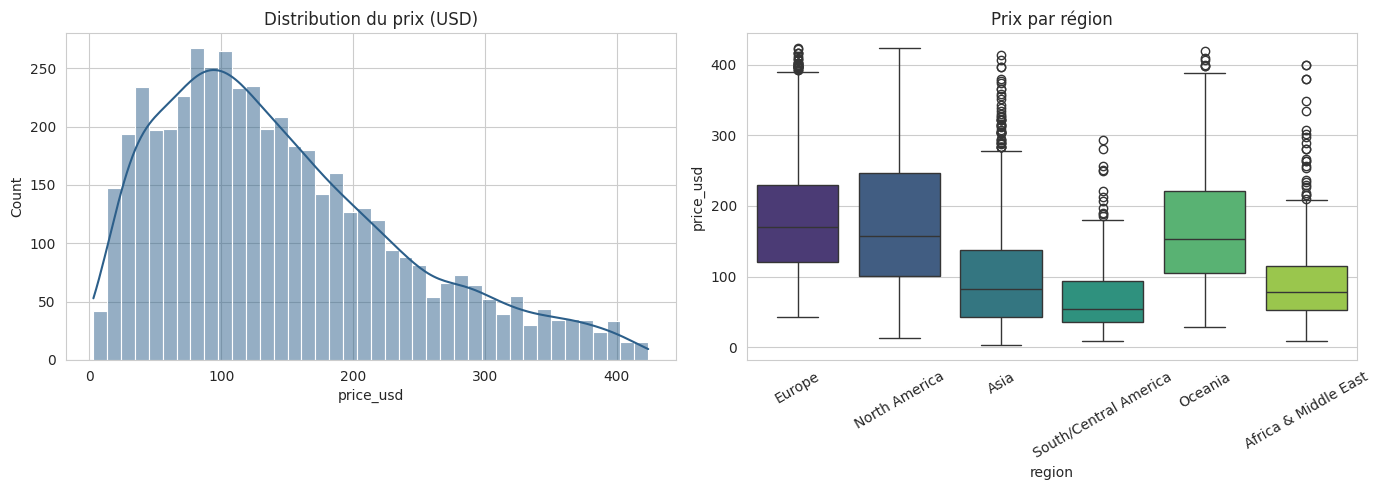

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["price_usd"], bins=40, kde=True, ax=axes[0], color="#2c5f8a")
axes[0].set_title("Distribution du prix (USD)")
sns.boxplot(x="region", y="price_usd", data=df_clean, ax=axes[1], palette="viridis")
axes[1].set_title("Prix par région")
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig("fig_prix_distribution_region.png", dpi=120)
plt.show()

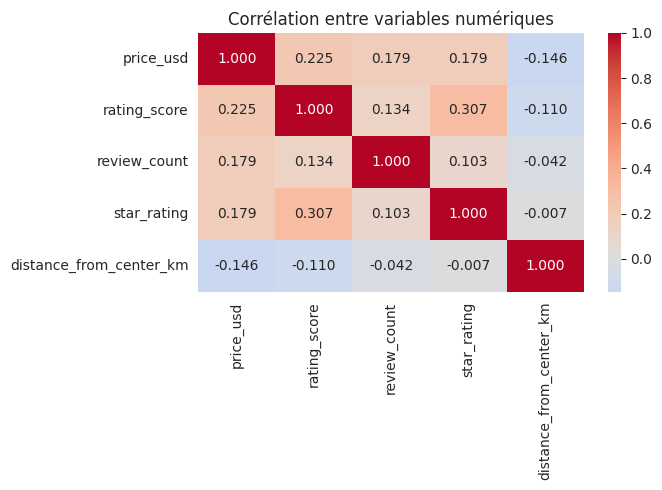

Corrélation prix / distance au centre : -0.1458


In [8]:
numeric_cols = ["price_usd", "rating_score", "review_count", "star_rating", "distance_from_center_km"]
corr = df_clean[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Corrélation entre variables numériques")
plt.tight_layout()
plt.savefig("fig_heatmap_correlation.png", dpi=120)
plt.show()

print("Corrélation prix / distance au centre :", round(corr.loc["price_usd", "distance_from_center_km"], 4))

In [9]:
amenity_cols = ["free_cancellation", "breakfast_included", "free_wifi",
                 "no_prepayment", "has_parking", "has_pool", "has_gym"]
amenity_price = df_clean.groupby("region")[amenity_cols].mean().round(2)
amenity_price

,free_cancellation,breakfast_included,free_wifi,no_prepayment,has_parking,has_pool,has_gym
region,,,,,,,
Africa & Middle East,0.53,0.28,0.0,0.26,0.00,0.02,0.0
Asia,0.62,0.16,0.0,0.29,0.00,0.02,0.0
Europe,0.21,0.17,0.0,0.07,0.00,0.00,0.0
North America,0.45,0.27,0.0,0.25,0.01,0.00,0.0
Oceania,0.44,0.05,0.0,0.23,0.01,0.00,0.0
South/Central America,0.61,0.34,0.0,0.45,0.01,0.00,0.0


## 4. Préparation pour le Machine Learning

In [10]:
features_num = ["rating_score", "review_count", "star_rating", "distance_from_center_km"]
features_bool = ["free_cancellation", "breakfast_included", "free_wifi",
                  "no_prepayment", "has_parking", "has_pool", "has_gym"]

# One-hot sur region (6 valeurs, peu coûteux) ET sur city (122 valeurs, comme
# dans la version précédente) pour pouvoir comparer les deux approches ensuite.
df_model = df_clean.copy()
for c in features_bool:
    df_model[c] = df_model[c].astype(int)

df_encoded = pd.get_dummies(df_model, columns=["region", "city"], drop_first=True)

feature_cols = features_num + features_bool + \
    [c for c in df_encoded.columns if c.startswith("region_") or c.startswith("city_")]

X = df_encoded[feature_cols]
y = df_encoded["price_usd"]

print("Nombre de features :", X.shape[1])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train :", X_train.shape, " Test :", X_test.shape)

Nombre de features : 137
Train : (3893, 137)  Test : (974, 137)


## 5. Modèles de régression

In [11]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"MAE  : {mae:.2f} USD")
    print(f"RMSE : {rmse:.2f} USD")
    print(f"R2   : {r2:.4f}\n")
    return mae, rmse, r2

In [12]:
# Modèle A : Régression Linéaire
modele_lr = LinearRegression()
modele_lr.fit(X_train, y_train)
pred_lr = modele_lr.predict(X_test)
mae_lr, rmse_lr, r2_lr = evaluate("Régression Linéaire", y_test, pred_lr)

--- Régression Linéaire ---
MAE  : 40.75 USD
RMSE : 54.33 USD
R2   : 0.6320



In [13]:
# Modèle B : Random Forest (baseline)
modele_rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
modele_rf.fit(X_train, y_train)
pred_rf = modele_rf.predict(X_test)
mae_rf, rmse_rf, r2_rf = evaluate("Random Forest", y_test, pred_rf)

--- Random Forest ---
MAE  : 38.65 USD
RMSE : 53.45 USD
R2   : 0.6438



In [14]:
# Modèle B-bis : Random Forest optimisé via GridSearchCV
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
}
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid, cv=5, scoring="r2", n_jobs=-1
)
grid_search.fit(X_train, y_train)
print("Meilleurs paramètres :", grid_search.best_params_)

modele_rf_opti = grid_search.best_estimator_
pred_rf_opti = modele_rf_opti.predict(X_test)
mae_rf_opti, rmse_rf_opti, r2_rf_opti = evaluate("Random Forest Optimisé", y_test, pred_rf_opti)

Meilleurs paramètres : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
--- Random Forest Optimisé ---
MAE  : 38.20 USD
RMSE : 52.67 USD
R2   : 0.6541



In [15]:
# Modèle C : Gradient Boosting
modele_gb = GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE)
modele_gb.fit(X_train, y_train)
pred_gb = modele_gb.predict(X_test)
mae_gb, rmse_gb, r2_gb = evaluate("Gradient Boosting", y_test, pred_gb)

--- Gradient Boosting ---
MAE  : 45.69 USD
RMSE : 59.27 USD
R2   : 0.5621



In [16]:
# Modèle D : XGBoost
modele_xgb = XGBRegressor(n_estimators=100, random_state=RANDOM_STATE, objective="reg:squarederror")
modele_xgb.fit(X_train, y_train)
pred_xgb = modele_xgb.predict(X_test)
mae_xgb, rmse_xgb, r2_xgb = evaluate("XGBoost", y_test, pred_xgb)

--- XGBoost ---
MAE  : 37.72 USD
RMSE : 52.49 USD
R2   : 0.6565



In [17]:
resultats = pd.DataFrame({
    "Modèle": ["Régression Linéaire", "Random Forest", "Random Forest Optimisé",
               "Gradient Boosting", "XGBoost"],
    "MAE": [mae_lr, mae_rf, mae_rf_opti, mae_gb, mae_xgb],
    "RMSE": [rmse_lr, rmse_rf, rmse_rf_opti, rmse_gb, rmse_xgb],
    "R2": [r2_lr, r2_rf, r2_rf_opti, r2_gb, r2_xgb],
}).sort_values("R2", ascending=False).reset_index(drop=True)

resultats

,Modèle,MAE,RMSE,R2
0,XGBoost,37.715763,52.493408,0.656464
1,Random Forest Optimisé,38.200264,52.674876,0.654085
2,Random Forest,38.647472,53.452531,0.643796
3,Régression Linéaire,40.747617,54.327898,0.632033
4,Gradient Boosting,45.688605,59.268751,0.562060


/tmp/ipykernel_647/3855356775.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=resultats, x="Modèle", y="R2", palette="mako")


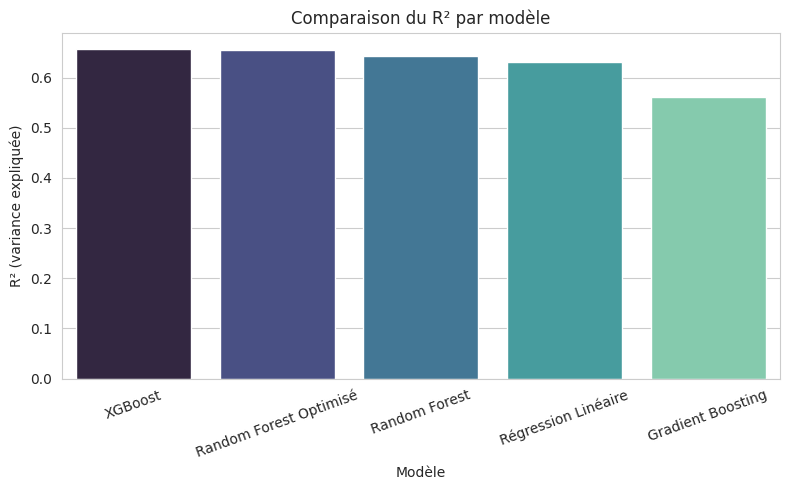

In [18]:
plt.figure(figsize=(8, 5))
sns.barplot(data=resultats, x="Modèle", y="R2", palette="mako")
plt.title("Comparaison du R² par modèle")
plt.ylabel("R² (variance expliquée)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("fig_comparaison_r2.png", dpi=120)
plt.show()

/tmp/ipykernel_647/2324450949.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15.values, y=top15.index, palette="crest")


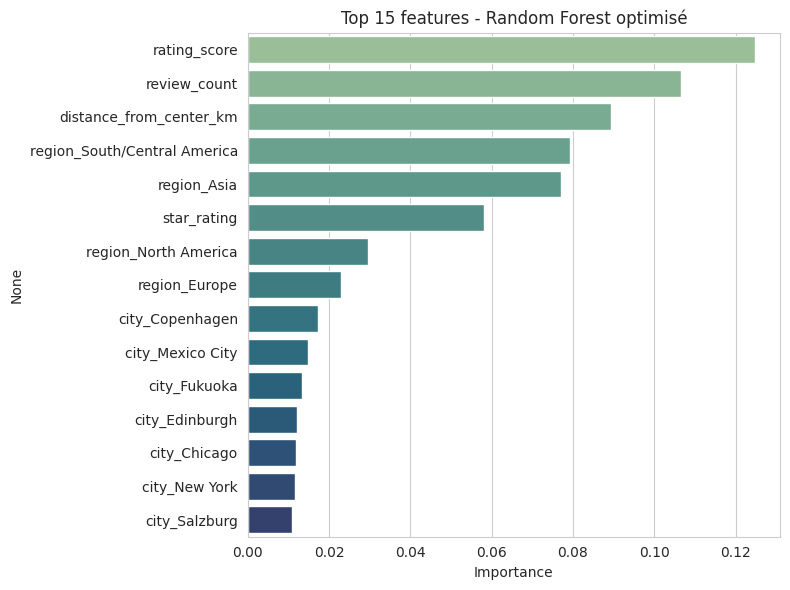

In [19]:
# Importance des features du Random Forest optimisé (top 15)
importances = pd.Series(modele_rf_opti.feature_importances_, index=feature_cols)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top15.values, y=top15.index, palette="crest")
plt.title("Top 15 features - Random Forest optimisé")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=120)
plt.show()

## 6. Clustering K-Means (segmentation)

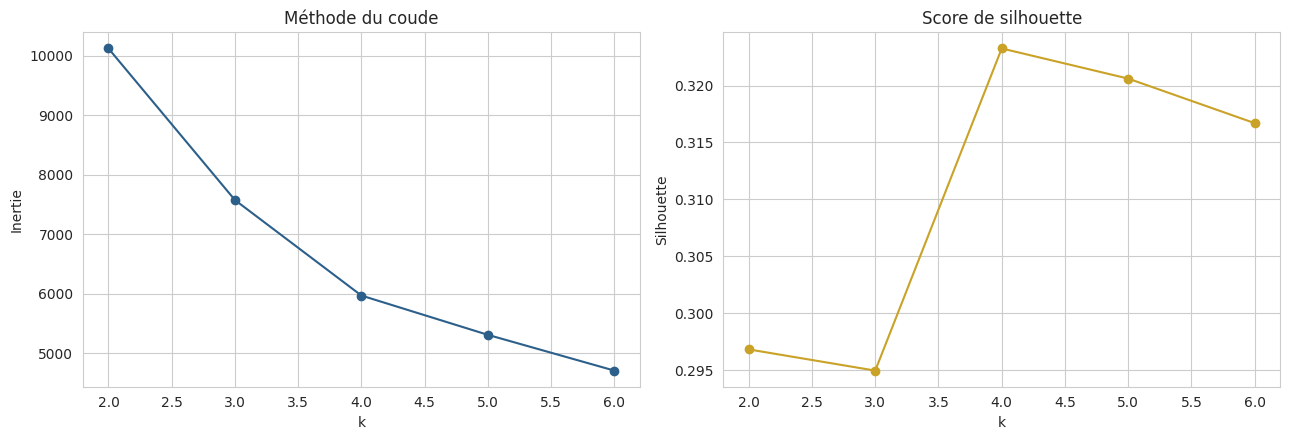

k=2 -> silhouette = 0.2968
k=3 -> silhouette = 0.2950
k=4 -> silhouette = 0.3233
k=5 -> silhouette = 0.3206
k=6 -> silhouette = 0.3167


In [20]:
cluster_features = ["price_usd", "rating_score", "star_rating"]
X_cluster_raw = df_clean[cluster_features]

scaler = StandardScaler()
X_cluster = scaler.fit_transform(X_cluster_raw)

inertias = []
silhouettes = []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, marker="o", color="#2c5f8a")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertie")

axes[1].plot(list(k_range), silhouettes, marker="o", color="#c9a227")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig("fig_elbow_silhouette.png", dpi=120)
plt.show()

for k, s in zip(k_range, silhouettes):
    print(f"k={k} -> silhouette = {s:.4f}")

In [21]:
# k=3 retenu pour coller à la structure métier (économique / moyen / haut de gamme)
k_final = 3
km_final = KMeans(n_clusters=k_final, random_state=RANDOM_STATE, n_init=10)
df_clean = df_clean.copy()
df_clean["cluster"] = km_final.fit_predict(X_cluster)

silhouette_final = silhouette_score(X_cluster, df_clean["cluster"])
print(f"Score de silhouette (k={k_final}) : {silhouette_final:.4f}")

profils = df_clean.groupby("cluster").agg(
    nb_hotels=("hotel_name", "count"),
    prix_moyen=("price_usd", "mean"),
    note_moyenne=("rating_score", "mean"),
    etoiles_moyennes=("star_rating", "mean"),
).round(2).sort_values("prix_moyen")
profils.index = ["Économique", "Milieu de gamme", "Haut de gamme"]
profils

Score de silhouette (k=3) : 0.2950


,nb_hotels,prix_moyen,note_moyenne,etoiles_moyennes
Économique,1237,99.11,7.06,2.76
Milieu de gamme,2328,101.29,8.54,3.87
Haut de gamme,1302,270.59,8.54,3.85


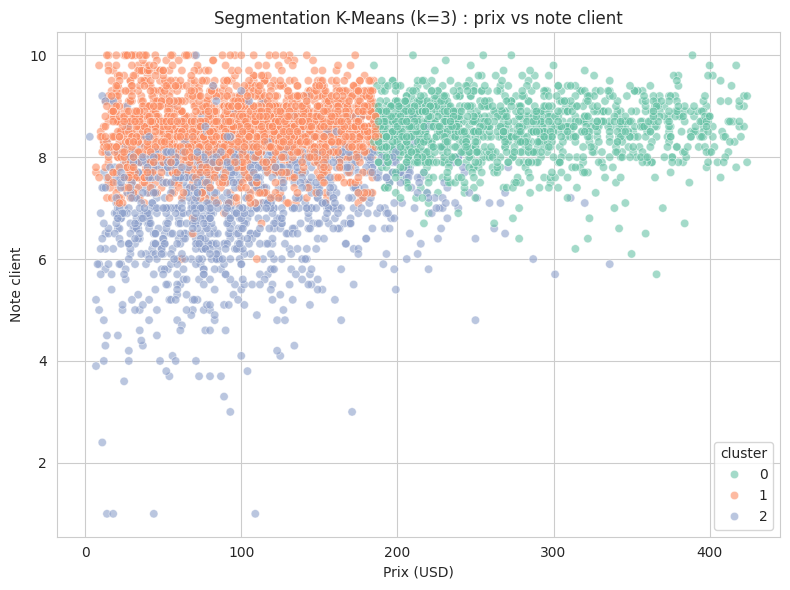

In [22]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_clean, x="price_usd", y="rating_score",
    hue="cluster", palette="Set2", alpha=0.6
)
plt.title(f"Segmentation K-Means (k={k_final}) : prix vs note client")
plt.xlabel("Prix (USD)")
plt.ylabel("Note client")
plt.tight_layout()
plt.savefig("fig_clusters.png", dpi=120)
plt.show()

## 7. Synthèse

- **Régression** : voir le tableau `resultats` en section 5 pour les métriques
  finales (MAE, RMSE, R²) des 5 modèles sur le nouveau dataset.
- **Clustering** : 3 segments identifiés (voir `profils`), score de silhouette
  affiché ci-dessus pour k=3.
- **Nouveautés exploitées** : `region` en complément de `city`, distance déjà
  propre en km, booléens d'équipements directement utilisables.
- **Limite assumée** : `property_type`, `original_price_usd`, `discount_pct`
  et `booked_today_count` restent peu remplies sur ce run — à réévaluer si un
  futur scraping améliore leur couverture, avant de les intégrer au modèle.